# Model size: 0.5B, 1.5B and 3B with the same recipe

Baselines.ipynb found that the same recipe on Qwen2.5-1.5B reaches a validation loss of 3.150 against 3.418 on the 0.5B, a far bigger step than doubling the data (~0.08) or growing the adapter (LoraRank.ipynb, ~0.01 per doubling). Here a third point is added, Qwen2.5-3B, and all three are trained on the same machine (the NAS GPU, mlx-cuda) so they are compared with each other:

- the same recipe (LoRA rank 8 on the last 16 layers, scale 20, lr 1e-5, effective batch 4, up to 3,500 steps), checkpoints measured on the full validation set (6 turns of context);
- at each model's best step, test perplexity of the base model and the adapter on my replies and on my friends', and the signal (decision 12).

The three models share the tokenizer, so losses are comparable token by token. Two things change besides size: the base model starts better before any training, and 16 adapted layers are a smaller share of a deeper model (24 layers in the 0.5B, 28 in the 1.5B, 36 in the 3B). The base-model numbers separate "starts better" from "learns more".

Memory: with batches of 2 the 1.5B ran out of the 3080's 10 GB, so all three use micro-batches of 1 with gradient accumulation (`--grad-accum 4`, effective batch 4) and gradient checkpointing (recomputes activations in the backward pass: less memory, same result). The 0.5B is retrained this way too, so the three runs share every setting but the base model.

## Prediction (written before running)

From the little we've seen, going to a slightly bigger model lowers the loss a lot, so I think the 3B should improve even more, although I'm unsure about the size of that improvement. Probably about the same improvement or a bit less, because from 0.5B to 1.5B the parameters triple and from 1.5B to 3B they only double. So I think the improvement will be a bit smaller, but there will be one. I also expect both to improve: the loss on my replies and on my friends'. Open question to analyse: why does a bigger model give better replies than a smaller one, when both adapters are trained on the same data?

In [1]:
import json, os, subprocess
from pathlib import Path
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
ROOT = Path("..").resolve()
R = ROOT / "experiments" / "results"
PY = os.environ.get("TLM_PY", "uv run python")              # NAS: TLM_PY=/opt/venv/bin/python
TURNS_V1 = "data/processed_v1_2026-10-17/turns.jsonl"
# size label, model, adapter name, gradient accumulation, layers in the model
MODELS = [
    ("0.5B", "mlx-community/Qwen2.5-0.5B-Instruct-4bit", "size_0.5b", 4, 24),
    ("1.5B", "mlx-community/Qwen2.5-1.5B-Instruct-4bit", "size_1.5b", 4, 28),
    ("3B", "mlx-community/Qwen2.5-3B-Instruct-4bit", "size_3b", 4, 36),
]

def run(cmd):
    """Run a command from the repo root, show its output here, and stop the notebook if it fails."""
    print("$", cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        if "Fetching" not in line and "█" not in line:
            print(line, end="", flush=True)
    if p.wait() != 0:
        raise RuntimeError(f"failed ({p.returncode}): {cmd}")

def best(name):
    d = json.load(open(R / f"checkpoints_{name}.json"))
    v = {int(k): x for k, x in d["valid"].items()}
    s = min(v, key=v.get)
    return s, v[s]

## Train, pick the checkpoint on validation, measure the signal on test

In [2]:
for label, model, name, accum, _ in MODELS:
    if not (ROOT / "adapters" / name / "0003500_adapters.safetensors").exists():
        run(f"{PY} scripts/train.py --name {name} --data data/dataset/session --model {model} --iters 3500 --grad-accum {accum} --grad-checkpoint")
    run(f"{PY} scripts/eval_checkpoints.py adapters/{name} --model {model} --data data/dataset/session/valid.jsonl --steps 500:3500:500 --out experiments/results/checkpoints_{name}.json")
    step, loss = best(name)
    print(f"{label}: best step {step}, valid {loss:.3f}")
    run(f"{PY} scripts/eval_signal.py --adapter adapters/{name} --step {step} --model {model} --turns {TURNS_V1} --out experiments/results/signal_size_{label}.json")

$ /opt/venv/bin/python scripts/eval_checkpoints.py adapters/size_0.5b --model mlx-community/Qwen2.5-0.5B-Instruct-4bit --data data/dataset/session/valid.jsonl --steps 500:3500:500 --out experiments/results/checkpoints_size_0.5b.json
step   500: loss 3.532
step  1000: loss 3.459
step  1500: loss 3.458
step  2000: loss 3.435
step  2500: loss 3.424
step  3000: loss 3.479
step  3500: loss 3.482
best: step 2500, loss 3.424
0.5B: best step 2500, valid 3.424
$ /opt/venv/bin/python scripts/eval_signal.py --adapter adapters/size_0.5b --step 2500 --model mlx-community/Qwen2.5-0.5B-Instruct-4bit --turns data/processed_v1_2026-10-17/turns.jsonl --out experiments/results/signal_size_0.5B.json
mine:    base 75.5 -> adapter 29.8 (60.5% drop)
friends: base 81.1 -> adapter 49.2 (39.3% drop)
signal: 21.2 points, 95% CI [15.4, 27.6]
$ /opt/venv/bin/python scripts/train.py --name size_1.5b --data data/dataset/session --model mlx-community/Qwen2.5-1.5B-Instruct-4bit --iters 3500 --grad-accum 4 --grad-check

## Summary

model  layers adapted  best valid |  test ppl: base me  adapter me  base fr.  adapter fr. |  drop me  drop fr.   signal         95% CI
 0.5B        16 of 24       3.424 |               75.5        29.8      81.1         49.2 |    60.5%     39.3%    21.2 [15.4, 27.6]
 1.5B        16 of 28       3.147 |               60.9        23.0      58.5         34.6 |    62.2%     40.8%    21.4 [15.3, 28.3]
   3B        16 of 36       3.018 |              132.0        20.7     122.9         30.2 |    84.3%     75.4%     8.9 [5.1, 13.9]
where the improvement comes from (test loss on my replies, nats per token)
model    base  adapter  gained by the adapter
 0.5B   4.324    3.394                  0.930
 1.5B   4.109    3.137                  0.973
   3B   4.883    3.031                  1.852


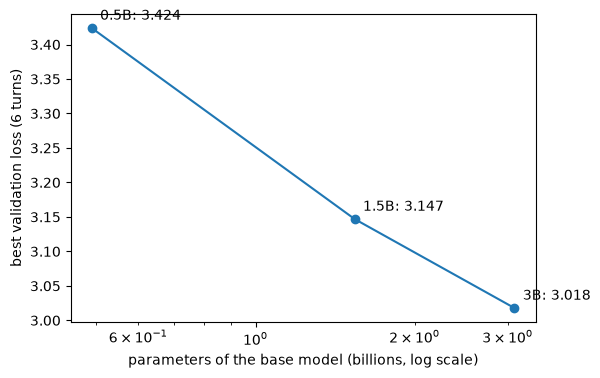

In [3]:
import math
import matplotlib.pyplot as plt

PARAMS = {"0.5B": 0.49, "1.5B": 1.54, "3B": 3.09}
rows = []
print(f"{'model':>5} {'layers adapted':>15} {'best valid':>11} | {'test ppl: base me':>18} {'adapter me':>11} {'base fr.':>9} {'adapter fr.':>12} | {'drop me':>8} {'drop fr.':>9} {'signal':>8} {'95% CI':>14}")
for label, model, name, accum, layers in MODELS:
    step, valid = best(name)
    s = json.load(open(R / f"signal_size_{label}.json"))
    p = s["perplexity"]
    rows.append((label, valid, s))
    print(f"{label:>5} {f'16 of {layers}':>15} {valid:>11.3f} | {p['base_me']:>18.1f} {p['adapter_me']:>11.1f} {p['base_friends']:>9.1f} {p['adapter_friends']:>12.1f} | "
          f"{s['drop']['me']:>8.1%} {s['drop']['friends']:>9.1%} {s['signal'] * 100:>7.1f} [{s['signal_ci'][0] * 100:.1f}, {s['signal_ci'][1] * 100:.1f}]")

print("\nwhere the improvement comes from (test loss on my replies, nats per token)")
print(f"{'model':>5} {'base':>7} {'adapter':>8} {'gained by the adapter':>22}")
for label, valid, s in rows:
    b, a = math.log(s["perplexity"]["base_me"]), math.log(s["perplexity"]["adapter_me"])
    print(f"{label:>5} {b:>7.3f} {a:>8.3f} {b - a:>22.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([PARAMS[r[0]] for r in rows], [r[1] for r in rows], marker="o")
for label, valid, _ in rows:
    ax.annotate(f"{label}: {valid:.3f}", (PARAMS[label], valid), textcoords="offset points", xytext=(6, 6))
ax.set_xscale("log"); ax.set_xlabel("parameters of the base model (billions, log scale)")
ax.set_ylabel("best validation loss (6 turns)")
plt.show()

## The signal in nats, independent of the starting point

In [ ]:
# The percentage signal compares relative drops from each base model, so it shrinks when a base
# model starts far off (the 3B base is worse than the 1.5B on WhatsApp). This version doesn't
# depend on the starting point: how much harder my friends' replies are than mine for the adapted
# model, minus the same gap for the base model, in nats per token (a difference in differences).
import sys, random
import numpy as np
sys.path.insert(0, str(ROOT))
from talk_like_me.sessions import test_sessions
from talk_like_me.stats import by_session, loss_over

ses_me, ses_fr = test_sessions(ROOT / TURNS_V1)
sessions = sorted(set(ses_me) | set(ses_fr))

def did(pe, chosen):
    s = {k: by_session(v, ses_me if k.endswith("_me") else ses_fr) for k, v in pe.items()}
    l = {k: loss_over(s[k], chosen) for k in s}
    return (l["adapter_friends"] - l["adapter_me"]) - (l["base_friends"] - l["base_me"])

print(f"{'model':>5} {'gap base (fr - me)':>19} {'gap adapted':>12} {'signal (nats)':>14} {'95% CI':>16}")
for label, *_ in MODELS:
    pe = json.load(open(R / f"signal_size_{label}.json"))["per_example"]
    s = {k: by_session(v, ses_me if k.endswith("_me") else ses_fr) for k, v in pe.items()}
    l = {k: loss_over(s[k], sessions) for k in s}
    value = did(pe, sessions)
    random.seed(0)
    boot = [did(pe, random.choices(sessions, k=len(sessions))) for _ in range(1000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"{label:>5} {l['base_friends'] - l['base_me']:>19.3f} {l['adapter_friends'] - l['adapter_me']:>12.3f} {value:>14.3f} [{lo:.3f}, {hi:.3f}]")


model  gap base (fr - me)  gap adapted  signal (nats)           95% CI
 0.5B               0.071        0.502          0.430 [0.314, 0.562]
 1.5B              -0.041        0.407          0.448 [0.329, 0.599]
   3B              -0.072        0.379          0.450 [0.253, 0.676]


## Conclusion

| Model | Layers adapted | Best valid | Test ppl, me (base to adapted) | Test ppl, friends (base to adapted) | Signal, % points | Signal, nats (95% CI) |
|---|---|---|---|---|---|---|
| 0.5B | 16 of 24 | 3.424 | 75.5 to 29.8 | 81.1 to 49.2 | 21.2 | 0.430 [0.314, 0.562] |
| 1.5B | 16 of 28 | 3.147 | 60.9 to 23.0 | 58.5 to 34.6 | 21.4 | 0.448 [0.329, 0.599] |
| 3B | 16 of 36 | 3.018 | 132.0 to 20.7 | 122.9 to 30.2 | 8.9 | 0.450 [0.253, 0.676] |

**Against the prediction.** Right: the 3B improves again, and by less than the previous step (-0.13 against -0.28; the log-scaling estimate in the literature review was ~2.99). Right: both my loss and my friends' improve.

**The percentage signal is misleading across models.** It falls to 8.9 points for the 3B, but that is the metric, not the model. The 3B base model is worse than the 1.5B on WhatsApp (perplexity 132 against 61), probably because as an assistant it expects longer, formal text. Starting that far off, both drops get close to 100% (84% and 75%) and their difference shrinks. Measured in nats, as how much harder my friends' replies are than mine for the adapted model minus the same gap for the base model, the signal is the same for the three sizes: 0.43, 0.45 and 0.45 nats per token, with overlapping intervals.

**Why the bigger model does better.** Not because it learns more of me: the part that is specifically mine (the signal in nats) doesn't grow with size. Not because the base starts better either (the 3B base starts worse). What grows is how well the adapted model predicts everyone's WhatsApp replies, mine and my friends' alike: 29.8, 23.0 and 20.7 on mine; 49.2, 34.6 and 30.2 on theirs. A bigger pretrained model, once the adapter moves it to the register, is simply a better predictor of this kind of text. This matches the literature (LIMA: knowledge comes from pretraining; Zhang et al. 2024: fine-tuning benefits more from model size than from data).

**Caveats.** One seed per size. The share of layers adapted shrinks with size (67%, 57%, 44%), which AllLayers.ipynb checks. Lower loss doesn't mean better answers: style and relevance were measured for the 1.5B in Baselines.ipynb, not for the 3B.